In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [ ]:
df=pd.read_csv("loan_data.csv")

In [ ]:
df.head()
df.isnull().sum()

age                       0
gender                    0
education                 0
income                    0
emp_exp                   0
home_ownership            0
loan_amnt                 0
loan_intent               0
loan_int_rate             0
loan_percent_income       0
cred_hist_length          0
credit_score              0
previous_loan_defaults    0
loan_status               0
dtype: int64

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   age                     45000 non-null  int64  
 1   gender                  45000 non-null  object 
 2   education               45000 non-null  object 
 3   income                  45000 non-null  int64  
 4   emp_exp                 45000 non-null  int64  
 5   home_ownership          45000 non-null  object 
 6   loan_amnt               45000 non-null  int64  
 7   loan_intent             45000 non-null  object 
 8   loan_int_rate           45000 non-null  float64
 9   loan_percent_income     45000 non-null  float64
 10  cred_hist_length        45000 non-null  int64  
 11  credit_score            45000 non-null  int64  
 12  previous_loan_defaults  45000 non-null  object 
 13  loan_status             45000 non-null  int64  
dtypes: float64(2), int64(7), object(5)
mem

handling missing values


In [ ]:
categorical_cols=df.select_dtypes(include=["object"]).columns
numerical_cols=df.select_dtypes(include=["number"]).columns

In [ ]:
categorical_cols

Index(['gender', 'education', 'home_ownership', 'loan_intent',
       'previous_loan_defaults'],
      dtype='object')

In [ ]:
numerical_cols

Index(['age', 'income', 'emp_exp', 'loan_amnt', 'loan_int_rate',
       'loan_percent_income', 'cred_hist_length', 'credit_score',
       'loan_status'],
      dtype='object')

#EDA (to know relationship btw features and analyse them by ploting them)

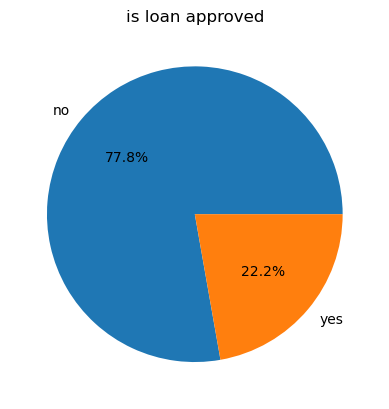

In [ ]:
classes_cnt=df["loan_status"].value_counts()
plt.pie(classes_cnt, labels=["no","yes"],autopct="%1.1f%%")
plt.title("is loan approved")
plt.show()

# analyse gender

<Axes: xlabel='gender', ylabel='count'>

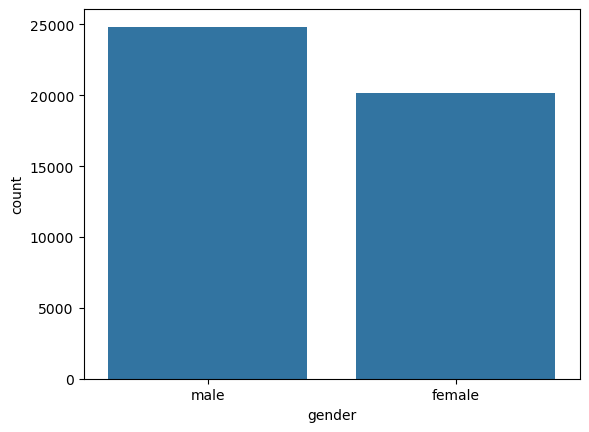

In [ ]:
gender_cnt=df["gender"].value_counts()
sns.barplot(gender_cnt)

# checking outliers

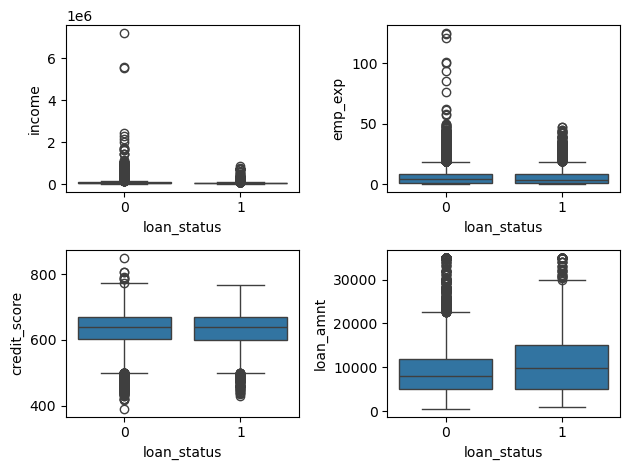

In [ ]:
fig, axes = plt.subplots(2,2)
sns.boxplot(ax=axes[0,0], data=df, x="loan_status",y="income")
sns.boxplot(ax=axes[0,1], data=df, x="loan_status",y="emp_exp")
sns.boxplot(ax=axes[1,0], data=df, x="loan_status",y="credit_score")
sns.boxplot(ax=axes[1,1], data=df, x="loan_status",y="loan_amnt")
plt.tight_layout()

# Encoding

In [ ]:
from sklearn.preprocessing import LabelEncoder , OneHotEncoder
le= LabelEncoder()
df["loan_status"]=le.fit_transform(df["loan_status"])
df["education"]=le.fit_transform(df["education"])
df.head()

,age,gender,education,income,emp_exp,home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cred_hist_length,credit_score,previous_loan_defaults,loan_status
0,22,female,4,71948,0,RENT,35000,PERSONAL,16.02,0.49,3,561,No,1
1,21,female,3,12282,0,OWN,1000,EDUCATION,11.14,0.08,2,504,Yes,0
2,25,female,3,12438,3,MORTGAGE,5500,MEDICAL,12.87,0.44,3,635,No,1
3,23,female,1,79753,0,RENT,35000,MEDICAL,15.23,0.44,2,675,No,1
4,24,male,4,66135,1,RENT,35000,MEDICAL,14.27,0.53,4,586,No,1


In [ ]:
cols=["gender","home_ownership","loan_intent","previous_loan_defaults"]
ohe=OneHotEncoder(drop="first",sparse_output=False, handle_unknown="ignore")
encoded=ohe.fit_transform(df[cols])
encoded_df=pd.DataFrame(encoded,columns=ohe.get_feature_names_out(cols),index=df.index)
df=pd.concat([df.drop(columns=cols),encoded_df],axis=1)

In [ ]:
df.head()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   age                          45000 non-null  int64  
 1   education                    45000 non-null  int64  
 2   income                       45000 non-null  int64  
 3   emp_exp                      45000 non-null  int64  
 4   loan_amnt                    45000 non-null  int64  
 5   loan_int_rate                45000 non-null  float64
 6   loan_percent_income          45000 non-null  float64
 7   cred_hist_length             45000 non-null  int64  
 8   credit_score                 45000 non-null  int64  
 9   loan_status                  45000 non-null  int64  
 10  gender_male                  45000 non-null  float64
 11  home_ownership_OTHER         45000 non-null  float64
 12  home_ownership_OWN           45000 non-null  float64
 13  home_ownership_R

# correlation heatmap

nums_col=df.select_dtypes(include="number")
corr_matrix=nums_col.corr()
plt.figure(figsize=(15,8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)


In [ ]:
# we want to see corelation of output feature with all other features
nums_col.corr()["loan_status"].sort_values(ascending=False)

loan_status                    1.000000
loan_percent_income            0.384880
loan_int_rate                  0.332005
home_ownership_RENT            0.255239
loan_amnt                      0.107714
loan_intent_MEDICAL            0.065195
loan_intent_HOMEIMPROVEMENT    0.033838
home_ownership_OTHER           0.013645
gender_male                   -0.000561
education                     -0.001747
credit_score                  -0.007647
cred_hist_length              -0.014851
emp_exp                       -0.020481
age                           -0.021476
loan_intent_PERSONAL          -0.022488
loan_intent_EDUCATION         -0.064006
loan_intent_VENTURE           -0.085992
home_ownership_OWN            -0.093666
income                        -0.135808
previous_loan_defaults_Yes    -0.543096
Name: loan_status, dtype: float64

In [ ]:
# train_test_split

In [ ]:
x=df.drop("loan_status",axis=1)
y=df["loan_status"]

x.head()
# if dimensions are large then do not apply knn bcz data become sparse

,age,education,income,emp_exp,loan_amnt,loan_int_rate,loan_percent_income,cred_hist_length,credit_score,gender_male,home_ownership_OTHER,home_ownership_OWN,home_ownership_RENT,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE,previous_loan_defaults_Yes
0,22,4,71948,0,35000,16.02,0.49,3,561,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
1,21,3,12282,0,1000,11.14,0.08,2,504,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,25,3,12438,3,5500,12.87,0.44,3,635,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,23,1,79753,0,35000,15.23,0.44,2,675,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
4,24,4,66135,1,35000,14.27,0.53,4,586,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0


In [ ]:
y.head()

0    1
1    0
2    1
3    1
4    1
Name: loan_status, dtype: int64

In [ ]:
x_train, x_test, y_train, y_test= train_test_split(x,y, test_size=0.2, random_state=42)
x_test.head()

,age,education,income,emp_exp,loan_amnt,loan_int_rate,loan_percent_income,cred_hist_length,credit_score,gender_male,home_ownership_OTHER,home_ownership_OWN,home_ownership_RENT,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE,previous_loan_defaults_Yes
37979,32,0,96865,10,7500,6.04,0.08,10,601,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
9911,24,0,56838,6,9000,11.49,0.16,4,647,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
43386,22,4,37298,0,5000,14.88,0.13,4,711,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
13822,23,1,39944,1,5000,13.99,0.13,3,597,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0
44810,42,3,67974,20,10000,15.41,0.15,11,586,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


In [ ]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled=scaler.transform(x_test)

x_test_scaled

array([[ 0.70710614, -1.17824216,  0.18954926, ..., -0.44855457,
        -0.45732836, -1.01415574],
       [-0.62237047, -1.17824216, -0.27833286, ..., -0.44855457,
        -0.45732836,  0.98604185],
       [-0.95473963,  1.52604332, -0.5067391 , ..., -0.44855457,
        -0.45732836, -1.01415574],
       ...,
       [-0.62237047,  1.52604332, -0.01986209, ..., -0.44855457,
        -0.45732836, -1.01415574],
       [ 1.7042136 , -1.17824216, -0.50856261, ..., -0.44855457,
        -0.45732836, -1.01415574],
       [-0.4561859 ,  0.84997195, -0.53107593, ..., -0.44855457,
        -0.45732836, -1.01415574]], shape=(9000, 19))

# training and evaluation

In [ ]:
# applyting logistic regression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix,accuracy_score,precision_score,recall_score,f1_score

log_model=LogisticRegression()
log_model.fit(x_train_scaled, y_train)

y_pred=log_model.predict(x_test_scaled)

# evaluation
print("Precision : ",precision_score(y_test, y_pred))
print("Recall : ",recall_score(y_test, y_pred))
print("Accuracy : ",accuracy_score(y_test, y_pred))
print("F1 Score : ",f1_score(y_test, y_pred))
print("CM : ",confusion_matrix(y_test, y_pred))




Precision :  0.7733402489626556
Recall :  0.7417910447761195
Accuracy :  0.8937777777777778
F1 Score :  0.7572371762315896
CM :  [[6553  437]
 [ 519 1491]]


In [ ]:
# applying knn
from sklearn.neighbors import KNeighborsClassifier

knn_model=KNeighborsClassifier(n_neighbors=3)
knn_model.fit(x_train_scaled, y_train)

y_pred=knn_model.predict(x_test_scaled)

# evaluation
print("Precision : ",precision_score(y_test, y_pred))
print("Recall : ",recall_score(y_test, y_pred))
print("Accuracy : ",accuracy_score(y_test, y_pred))
print("F1 Score : ",f1_score(y_test, y_pred))
print("CM : ",confusion_matrix(y_test, y_pred))




Precision :  0.7809206877426511
Recall :  0.700497512437811
Accuracy :  0.8892222222222222
F1 Score :  0.7385260949383687
CM :  [[6595  395]
 [ 602 1408]]


In [ ]:
# applying naive bayes
from sklearn.naive_bayes import GaussianNB

NB_model=GaussianNB()
NB_model.fit(x_train_scaled, y_train)

y_pred=NB_model.predict(x_test_scaled)

# evaluation
print("Precision : ",precision_score(y_test, y_pred))
print("Recall : ",recall_score(y_test, y_pred))
print("Accuracy : ",accuracy_score(y_test, y_pred))
print("F1 Score : ",f1_score(y_test, y_pred))
print("CM : ",confusion_matrix(y_test, y_pred))




Precision :  0.47186147186147187
Recall :  0.9761194029850746
Accuracy :  0.7506666666666667
F1 Score :  0.6361867704280155
CM :  [[4794 2196]
 [  48 1962]]


In [ ]:
# Feature Engineering

In [ ]:
df["credit_score_sq"]=df["credit_score"] **2
x=df.drop(columns=["loan_status","credit_score"])
y=df["loan_status"]
x_train, x_test, y_train, y_test= train_test_split(x,y, test_size=0.2, random_state=42)

scaler=StandardScaler()
x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled=scaler.transform(x_test)



In [ ]:
# applyting logistic regression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix,accuracy_score,precision_score,recall_score,f1_score

log_model=LogisticRegression()
log_model.fit(x_train_scaled, y_train)

y_pred=log_model.predict(x_test_scaled)

# evaluation
print("Precision : ",precision_score(y_test, y_pred))
print("Recall : ",recall_score(y_test, y_pred))
print("Accuracy : ",accuracy_score(y_test, y_pred))
print("F1 Score : ",f1_score(y_test, y_pred))
print("CM : ",confusion_matrix(y_test, y_pred))




Precision :  0.7733402489626556
Recall :  0.7417910447761195
Accuracy :  0.8937777777777778
F1 Score :  0.7572371762315896
CM :  [[6553  437]
 [ 519 1491]]


# project done
